# Preparação dos Dados — do OHLCV bruto ao tensor de treino (CNN+LSTM)

**Aula 2 · Predição de operação em um único ativo:** amanhã compro, vendo ou mantenho?

Este notebook implementa, etapa por etapa, o pipeline apresentado nos slides:

| # | Etapa | Onde o futuro pode vazar |
|---|-------|--------------------------|
| 1 | Dados brutos (OHLCV ajustado) | dados não ajustados por splits |
| 2 | Features (retornos, vol, indicadores) | janelas centradas, `shift(-1)` |
| 3 | Rotulagem (threshold / triple barrier) | **aqui o futuro entra de propósito, só no alvo** |
| 4 | Split temporal + purging + embargo | rótulo do treino sobrepondo o teste |
| 5 | Normalização (scaler só no treino) | `scaler.fit(série inteira)` |
| 6 | Janelamento (T, F) | janela cruzando a fronteira treino/teste |
| 7 | Tensores X:(N,T,F), y:(N,3) + testes de sanidade | — |

> **Ordem importa:** features → rótulos → split → scaler → janelas. Nunca o contrário.

In [49]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from dataclasses import dataclass

pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 40)
np.random.seed(42)

# ---- Hiperparâmetros da preparação (fixe-os por critério econômico, não olhando o teste) ----
H       = 5      # horizonte do rótulo, em dias
K       = 1.0    # multiplicador da volatilidade no threshold θ
T       = 30     # dias por janela
EMBARGO = 5      # dias extras de lacuna entre blocos
CLIP_Z  = 5.0    # recorte de outliers após z-score

## 1 · Dados brutos: OHLCV diário

Use um único ativo líquido com 8–10 anos de histórico e **preços ajustados** por splits e
dividendos.

A célula abaixo baixa dados reais com `yfinance`. Se a rede ou a biblioteca falharem, ela
**levanta erro e para** — de propósito. Não existe plano B que gere série artificial: um pipeline
que silenciosamente troca dado real por dado inventado produz backtest de ficção, e a ficção é
indistinguível do resultado verdadeiro no gráfico. Falhar alto é a única saída honesta.

> 💡 Sem internet no laboratório? Use o parquet que `coleta_dados_b3.ipynb` gravou em
> `data/raw/b3_cotacoes.parquet` — é dado **real**, coletado antes. O que não se faz é substituir
> mercado por ruído sorteado.

In [ ]:
def load_real(ticker="PETR4.SA", start="2016-01-01"):
    """OHLCV diário ajustado (auto_adjust=True: splits E proventos embutidos no preço).

    Não tem tratamento de exceção de propósito. Se o download falhar, o notebook
    PARA aqui, com a mensagem original do erro. A alternativa -- cair num gerador
    de série artificial -- faria todo o resto do pipeline rodar bonito sobre ruído
    sorteado, e o backtest da aula seguinte mediria a lucratividade de um sorteio.
    """
    import yfinance as yf
    df = yf.download(ticker, start=start, auto_adjust=True, progress=False)
    if df is None or df.empty:
        raise RuntimeError(
            f"yfinance devolveu tabela vazia para {ticker}. Verifique o ticker e a rede. "
            "Alternativa com dado REAL: leia data/raw/b3_cotacoes.parquet, gerado por "
            "coleta_dados_b3.ipynb.")
    if isinstance(df.columns, pd.MultiIndex):
        df.columns = df.columns.get_level_values(0)
    df = df.rename(columns=str.lower)[["open", "high", "low", "close", "volume"]]
    df.index.name = "date"
    return df.dropna()


# O ticker fica em UMA variável, e ela viaja junto com os tensores (última célula).
# Sem isso o notebook de treino não tem como saber de qual papel são os rótulos --
# e aplicar o sinal de um ativo ao preço de outro é um erro que não dá mensagem.
TICKER = "PETR4.SA"

raw = load_real(TICKER)
raw_backup = raw.copy()          # cópia crua, antes de qualquer transformação

print(f"{TICKER} | {len(raw)} linhas | "
      f"{raw.index.min().date()} → {raw.index.max().date()}")
raw.head()

### Verificações obrigatórias

Datas duplicadas/faltantes, valores não positivos, coerência de High/Low e saltos absurdos (split não ajustado ou erro da fonte).

In [51]:
def check_ohlcv(df, jump_thr=0.30):
    problems = {}
    problems["datas_duplicadas"] = int(df.index.duplicated().sum())
    problems["nao_monotonico"]   = not df.index.is_monotonic_increasing
    gaps = df.index.to_series().diff().dt.days
    problems["buracos_>5_dias"]  = int((gaps > 5).sum())          # feriados longos são raros; buracos maiores merecem olhar
    problems["preco_nao_positivo"] = int((df[["open", "high", "low", "close"]] <= 0).any(axis=1).sum())
    problems["volume_nao_positivo"] = int((df["volume"] <= 0).sum())
    problems["high_incoerente"] = int((df["high"] < df[["open", "close"]].max(axis=1)).sum())
    problems["low_incoerente"]  = int((df["low"]  > df[["open", "close"]].min(axis=1)).sum())
    problems["saltos_>30%"]     = int((df["close"].pct_change().abs() > jump_thr).sum())
    return pd.Series(problems, name="ocorrências")

check_ohlcv(raw)

datas_duplicadas           0
nao_monotonico         False
buracos_>5_dias            0
preco_nao_positivo         0
volume_nao_positivo       10
high_incoerente           13
low_incoerente            18
saltos_>30%                0
Name: ocorrências, dtype: object

## Por que não alimentar a rede com preço

Preço é não-estacionário; o log-retorno $r_t = \ln(P_t / P_{t-1})$ oscila em torno de zero, tem escala comparável ao longo dos anos e é aditivo no tempo.

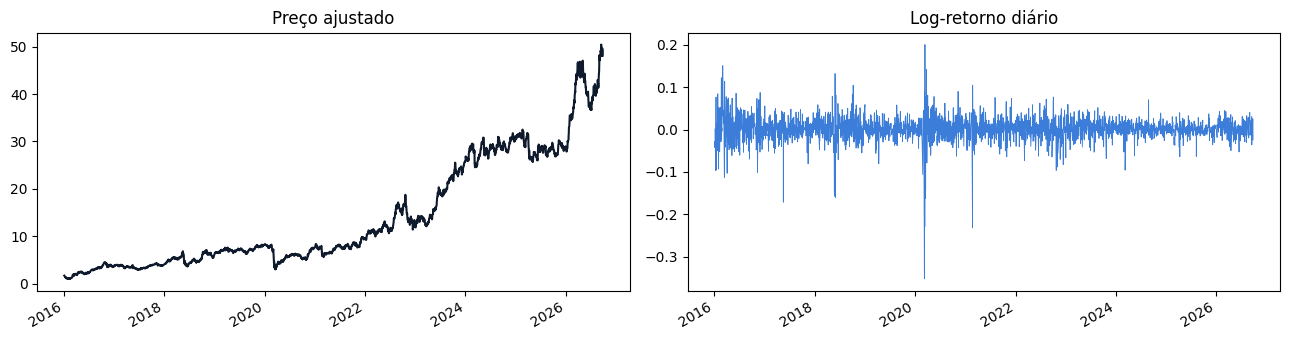

In [52]:
fig, ax = plt.subplots(1, 2, figsize=(13, 3.5))
raw["close"].plot(ax=ax[0], color="#0F1B2D", title="Preço ajustado")
np.log(raw["close"]).diff().plot(ax=ax[1], color="#3B7DD8", lw=0.6, title="Log-retorno diário")
for a in ax: a.set_xlabel("")
plt.tight_layout(); plt.show()

## 2 · Features

Três regras:

1. **Só passado** — a linha $t$ usa dados de $t, t-1, \dots$; nunca $t+1$. Todo `rolling` termina em $t$.
2. **Sem níveis absolutos** — tudo é retorno, razão ou diferença normalizada. `SMA20` é nível; `C/SMA20 − 1` é feature.
3. **Descarte o warm-up** — as primeiras linhas com `NaN` são removidas, não preenchidas com zero.

Como cada linha só olha para trás, é permitido calcular as features sobre a série inteira **antes** do split.

In [53]:
def rsi(close, n=14):
    d = close.diff()
    up, dn = d.clip(lower=0), -d.clip(upper=0)
    rs = up.ewm(alpha=1 / n, adjust=False).mean() / dn.ewm(alpha=1 / n, adjust=False).mean()
    return 100 - 100 / (1 + rs)

def build_features(df):
    o, h, l, c, v = df["open"], df["high"], df["low"], df["close"], df["volume"]
    f = pd.DataFrame(index=df.index)

    # --- retornos e volatilidade ---
    f["ret_1"] = np.log(c / c.shift(1))
    for k in (5, 10, 20):
        f[f"ret_{k}"] = np.log(c / c.shift(k))
    f["vol_10"] = f["ret_1"].rolling(10).std()
    f["vol_20"] = f["ret_1"].rolling(20).std()
    f["vol_ratio"] = f["vol_10"] / f["vol_20"]
    f["range"] = (h - l) / c
    f["gap"] = (o - c.shift(1)) / c.shift(1)
    f["body"] = (c - o) / (h - l).replace(0, np.nan)
    f["ret_1_z"] = (f["ret_1"] - f["ret_1"].rolling(20).mean()) / f["vol_20"]

    # --- tendência ---
    sma20, sma50 = c.rolling(20).mean(), c.rolling(50).mean()
    f["dist_sma20"] = c / sma20 - 1
    f["dist_sma50"] = c / sma50 - 1
    ema12, ema26 = c.ewm(span=12, adjust=False).mean(), c.ewm(span=26, adjust=False).mean()
    macd = ema12 - ema26
    f["macd_hist"] = (macd - macd.ewm(span=9, adjust=False).mean()) / c
    f["sma20_slope"] = sma20 / sma20.shift(5) - 1

    # --- osciladores ---
    f["rsi"] = rsi(c, 14) / 50 - 1                                   # [-1, 1]
    bb_mid, bb_sd = c.rolling(20).mean(), c.rolling(20).std()
    f["pct_b"] = (c - (bb_mid - 2 * bb_sd)) / (4 * bb_sd)
    f["bb_width"] = 4 * bb_sd / c
    lo14, hi14 = l.rolling(14).min(), h.rolling(14).max()
    f["stoch_k"] = (c - lo14) / (hi14 - lo14).replace(0, np.nan) * 2 - 1

    # --- volume ---
    # Volume ZERO nao e "nada foi negociado e isso e um numero": e ausencia de
    # dado (leilao sem negocio, papel suspenso). Tratar como zero literal produz
    # log(0) = -inf em dlog_vol -- e `inf` NAO e removido por dropna(), atravessa
    # o pipeline inteiro e destroi a media/desvio do scaler (ver §5).
    v_pos = v.replace(0, np.nan)
    f["vol_rel"] = v / v.rolling(20).mean().replace(0, np.nan)
    f["dlog_vol"] = np.log(v_pos / v_pos.shift(1))

    # --- calendário ---
    dow = df.index.dayofweek
    f["dow_sin"] = np.sin(2 * np.pi * dow / 5)
    f["dow_cos"] = np.cos(2 * np.pi * dow / 5)
    return f

features = build_features(raw)
print("features:", list(features.columns))
print("linhas com NaN (warm-up ou dado ausente):", int(features.isna().any(axis=1).sum()))

# Checagem que faltava: `inf` sobrevive ao dropna() e so aparece la na frente,
# como NaN no tensor. Conte aqui, onde ainda e barato descobrir de qual coluna veio.
inf_por_col = np.isinf(features.to_numpy(dtype="float64")).sum(axis=0)
inf_por_col = pd.Series(inf_por_col, index=features.columns)
print("valores infinitos por feature:",
      inf_por_col[inf_por_col > 0].to_dict() or "nenhum")
print("dias de volume zero em raw:", int((raw["volume"] == 0).sum()))

features: ['ret_1', 'ret_5', 'ret_10', 'ret_20', 'vol_10', 'vol_20', 'vol_ratio', 'range', 'gap', 'body', 'ret_1_z', 'dist_sma20', 'dist_sma50', 'macd_hist', 'sma20_slope', 'rsi', 'pct_b', 'bb_width', 'stoch_k', 'vol_rel', 'dlog_vol', 'dow_sin', 'dow_cos']
linhas com NaN (warm-up ou dado ausente): 79
valores infinitos por feature: nenhum
dias de volume zero em raw: 10


### Teste da série truncada (regra 1)

Recalcule as features com a série cortada em um dia $t$ qualquer. A linha $t$ tem que ser idêntica à da série completa. Se não for, alguma feature está olhando para frente.

In [54]:
def truncation_test(df, builder, n_checks=5, seed=0):
    rng = np.random.default_rng(seed)
    full = builder(df)
    for t in rng.choice(np.arange(100, len(df)), n_checks, replace=False):
        part = builder(df.iloc[: t + 1])
        assert np.allclose(full.iloc[t].values, part.iloc[t].values, equal_nan=True), f"vazamento na linha {df.index[t].date()}"
    return "OK: nenhuma feature usa o futuro"

truncation_test(raw, build_features)

'OK: nenhuma feature usa o futuro'

### Correlação entre features

Pares com |ρ| > 0,95 dizem quase a mesma coisa; remova um deles.

In [55]:
corr = features.corr().abs()
upper = corr.where(np.triu(np.ones(corr.shape, bool), k=1))
redundant = [(a, b, round(float(upper.loc[a, b]), 3)) for a in upper.index for b in upper.columns if upper.loc[a, b] > 0.95]
print("pares redundantes:", redundant or "nenhum")

pares redundantes: nenhum


## 3 · Rotulagem

Aqui o futuro entra **de propósito** — apenas no alvo. Duas opções:

**(a) Threshold sobre retorno futuro:** $R_t = \ln(C_{t+h}/C_t)$, comparado com $\theta_t = k \cdot \text{vol}_{20}(t) \cdot \sqrt{h}$.
θ proporcional à volatilidade evita que anos calmos virem só "mantém" e anos de crise virem só compra/venda.

**(b) Triple Barrier (López de Prado):** o rótulo é a primeira barreira tocada — alvo $C_t(1+\theta)$, stop $C_t(1-\theta)$ ou o limite de tempo $t+h$. Usa High/Low para checar o toque.

Codificação: `0 = venda`, `1 = mantém`, `2 = compra`. As últimas $h$ linhas não têm futuro conhecido e são descartadas.

In [56]:
CLASSES = {0: "venda", 1: "mantém", 2: "compra"}

def theta_series(features, k=K, h=H):
    return k * features["vol_20"] * np.sqrt(h)

def label_threshold(close, theta, h=H):
    fwd = np.log(close.shift(-h) / close)
    y = pd.Series(1, index=close.index, dtype="float")
    y[fwd > theta] = 2
    y[fwd < -theta] = 0
    y[fwd.isna() | theta.isna()] = np.nan
    return y

def label_triple_barrier(df, theta, h=H, tie_break_sign=False):
    c, hi, lo = df["close"].values, df["high"].values, df["low"].values
    th = theta.values
    n = len(c)
    y = np.full(n, np.nan)
    for t in range(n - h):
        if np.isnan(th[t]):
            continue
        up, dn = c[t] * (1 + th[t]), c[t] * (1 - th[t])
        label = 1
        for j in range(t + 1, t + h + 1):
            hit_up, hit_dn = hi[j] >= up, lo[j] <= dn
            if hit_up and hit_dn:          # ambos no mesmo dia: assume o pior caso (stop)
                label = 0; break
            if hit_up:
                label = 2; break
            if hit_dn:
                label = 0; break
        if label == 1 and tie_break_sign:  # variante: sinal do retorno final
            label = 2 if c[t + h] > c[t] else 0
        y[t] = label
    return pd.Series(y, index=df.index)

theta = theta_series(features)
y_thr = label_threshold(raw["close"], theta)
y_tb  = label_triple_barrier(raw, theta)

dist = pd.DataFrame({
    "threshold": y_thr.value_counts(normalize=True).sort_index(),
    "triple_barrier": y_tb.value_counts(normalize=True).sort_index(),
}).rename(index=CLASSES).round(3)
dist

,threshold,triple_barrier
venda,0.126,0.230
mantém,0.680,0.431
compra,0.194,0.339


### Classes desbalanceadas

"Mantém" domina. Responder "mantém" para tudo já dá a acurácia da classe majoritária — sem aprender nada. Por isso:

- **pesos na loss**: $w_c = N / (3 \cdot N_c)$, calculados **só no treino** (feito na seção 4);
- métrica correta desde já: **F1 por classe** e matriz de confusão, nunca acurácia global;
- nada de SMOTE em sequências temporais.

Escolha aqui qual rotulagem seguir para o resto do notebook.

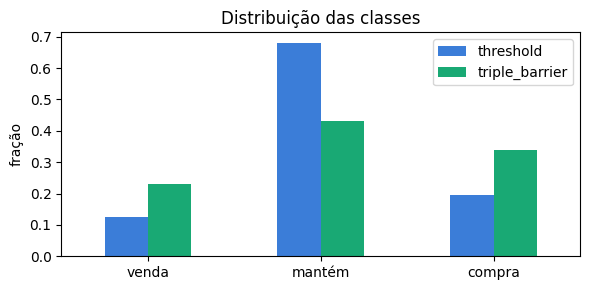

In [57]:
LABELING = "triple_barrier"          # ou "threshold"
y_all = (y_tb if LABELING == "triple_barrier" else y_thr).rename("y")

ax = dist.plot.bar(figsize=(6, 3), color=["#3B7DD8", "#19A974"], rot=0, title="Distribuição das classes")
ax.set_ylabel("fração"); plt.tight_layout(); plt.show()

### Montagem da tabela final e descarte do warm-up e das últimas h linhas

In [58]:
FEATURES = list(features.columns)
data = features.join(y_all)
n_before = len(data)

# `inf` primeiro, `dropna` depois -- nunca o contrario: dropna() NAO remove
# infinito, e um unico inf faz a media do scaler virar inf e o desvio virar NaN,
# transformando a coluna inteira em NaN nos tensores (§5).
n_inf = int(np.isinf(data[FEATURES].to_numpy(dtype="float64")).sum())
data = data.replace([np.inf, -np.inf], np.nan)
data = data.dropna()                        # warm-up (início), sem rótulo (fim), ausências

# Porteiro: a partir daqui nada entra no scaler nem na rede sem ser finito.
assert np.isfinite(data[FEATURES].to_numpy(dtype="float64")).all(), \
    "sobrou valor não finito na tabela final"

print(f"{n_before} → {len(data)} linhas | {len(FEATURES)} features | "
      f"{data.index.min().date()} → {data.index.max().date()}")
print(f"infinitos convertidos em NaN antes do dropna: {n_inf}")
data.tail(3)

2675 → 2591 linhas | 23 features | 2016-03-16 → 2026-09-18
infinitos convertidos em NaN antes do dropna: 0


,ret_1,ret_5,ret_10,ret_20,vol_10,vol_20,vol_ratio,range,gap,body,ret_1_z,dist_sma20,dist_sma50,macd_hist,sma20_slope,rsi,pct_b,bb_width,stoch_k,vol_rel,dlog_vol,dow_sin,dow_cos,y
date,,,,,,,,,,,,,,,,,,,,,,,,
2026-09-16,-0.035934,0.004739,0.037274,0.163702,0.020585,0.020832,0.988172,0.027955,-0.009716,-0.948527,-2.117886,0.061913,0.144470,0.004952,0.048059,0.312052,0.727786,0.255955,0.577320,1.074180,0.119262,0.587785,-0.809017,1.0
2026-09-17,-0.000823,-0.010437,0.008470,0.150979,0.018748,0.020907,0.896745,0.025509,-0.012744,0.467743,-0.400425,0.053210,0.138085,0.002416,0.045174,0.306926,0.703170,0.248666,0.482673,0.675945,-0.480918,-0.587785,-0.809017,1.0
2026-09-18,-0.002265,-0.010257,0.019572,0.121033,0.018131,0.020456,0.886336,0.011959,-0.004320,0.172411,-0.406578,0.044570,0.129963,0.000184,0.041557,0.291977,0.674321,0.244768,0.309262,1.090233,0.486173,-0.951057,0.309017,1.0


### ⚠️ `inf` não é `NaN` — e foi isso que quebrou este notebook

Esta seção ganhou uma checagem e um `assert` por causa de um defeito real, que vale mais
contado do que escondido.

`dlog_vol` era `np.log(v / v.shift(1))`. Em dias de **volume zero** — leilão sem negócio,
papel suspenso — isso dá `log(0) = -inf` (ou `+inf` no dia seguinte). E aí veio a parte
cara:

1. `dropna()` **não remove infinito**. `inf` é um `float` perfeitamente válido; só `NaN`
   é ausência. As linhas passaram pelo filtro.
2. No scaler (§5), `mean()` de uma coluna com `inf` virou `inf`, e `std()` virou `NaN`.
3. `(x - inf) / NaN` = `NaN` **para a coluna inteira** — nos três blocos.
4. Resultado: **63.990 `NaN` em `X_train`**. Toda janela continha `NaN`, e a primeira
   época de treino devolveria `loss = nan` sem nenhuma pista de onde.

Repare na assimetria do estrago: **um** valor infinito em **uma** coluna, e o tensor
inteiro fica inutilizável. E o `check_ohlcv` da §1 **já contava** os dias de volume não
positivo — ninguém agiu sobre a contagem. Detectar não serve de nada sem a ação
correspondente.

**A correção tem duas partes**, e as duas importam:

- **Na origem**: volume zero passa a ser `NaN` (ausência de dado, que é o que ele é), e
  não zero literal. Assim o problema vira uma linha descartada pelo `dropna` — o mesmo
  tratamento do warm-up.
- **No portão**: `replace([inf, -inf], nan)` **antes** do `dropna`, mais um `assert` de
  finitude. A primeira correção resolve a causa conhecida; a segunda pega a próxima, que
  vai vir de outra divisão com denominador zero que ainda não imaginamos.

> 🎯 Pergunte-se, em qualquer pipeline: **quais das minhas colunas são razões ou
> logaritmos?** Cada uma tem um denominador que pode zerar. `body` e `stoch_k` aqui já
> usavam `.replace(0, np.nan)` no denominador — a proteção certa, aplicada em dois
> lugares e esquecida no terceiro. É assim que esse tipo de defeito sobrevive: não por
> ignorância, por inconsistência.

## 4 · Split temporal, purging e embargo

Nunca embaralhe. O teste é o futuro do treino, com uma lacuna entre eles:

- **Purging** — o rótulo do dia $t$ usa $C_{t+h}$; as últimas $h$ linhas do treino "sabem" o início do teste. Descarte-as.
- **Embargo** — alguns dias extras de lacuna protegem contra autocorrelação residual (janelas vizinhas são quase idênticas).

Primeiro um split simples (treino / validação / teste), depois o gerador de janelas **walk-forward**.

In [59]:
@dataclass
class Split:
    train: pd.DataFrame
    val: pd.DataFrame
    test: pd.DataFrame

def temporal_split(data, val_start, test_start, h=H, embargo=EMBARGO):
    gap = h + embargo
    train = data.loc[: val_start].iloc[:-gap]                      # purging + embargo antes da validação
    val   = data.loc[val_start: test_start].iloc[:-gap]            # idem antes do teste
    test  = data.loc[test_start:]
    return Split(train, val, test)

def describe_split(sp):
    rows = []
    for name, blk in (("treino", sp.train), ("validação", sp.val), ("teste", sp.test)):
        d = blk["y"].value_counts(normalize=True).reindex([0, 1, 2]).fillna(0)
        rows.append({"bloco": name, "início": blk.index.min().date(), "fim": blk.index.max().date(), "n": len(blk),
                     "venda": round(d[0], 3), "mantém": round(d[1], 3), "compra": round(d[2], 3)})
    return pd.DataFrame(rows).set_index("bloco")

last_year = data.index.max().year
sp = temporal_split(data, val_start=f"{last_year - 1}-01-01", test_start=f"{last_year}-01-01")
describe_split(sp)

,início,fim,n,venda,mantém,compra
bloco,,,,,,
treino,2016-03-16,2024-12-12,2152,0.224,0.440,0.336
validação,2025-01-02,2025-12-12,240,0.300,0.438,0.262
teste,2026-01-02,2026-09-18,179,0.223,0.330,0.447


**Datas nas pontas:** confirme com os olhos que `treino < lacuna < validação < lacuna < teste`. A célula acima já mostra a distribuição por bloco; diferenças grandes indicam mudança de regime, não erro — mas você precisa saber disso antes de treinar.

In [60]:
def walk_forward(data, first_test_year, h=H, embargo=EMBARGO, val_months=12):
    '''Gera (treino, validação, teste) ano a ano. Cada bloco de teste é fora da amostra de verdade.'''
    gap = h + embargo
    for year in range(first_test_year, data.index.max().year + 1):
        test_start = pd.Timestamp(f"{year}-01-01")
        val_start = test_start - pd.DateOffset(months=val_months)
        train = data.loc[: val_start].iloc[:-gap]
        val = data.loc[val_start: test_start].iloc[:-gap]
        test = data.loc[test_start: pd.Timestamp(f"{year}-12-31")]
        if len(train) < 500 or len(test) == 0:
            continue
        yield year, Split(train, val, test)

for year, s in walk_forward(data, first_test_year=data.index.min().year + 4):
    print(f"testa {year}: treino {s.train.index.min().date()}→{s.train.index.max().date()} ({len(s.train)}) | "
          f"val →{s.val.index.max().date()} ({len(s.val)}) | teste {s.test.index.min().date()}→{s.test.index.max().date()} ({len(s.test)})")

testa 2020: treino 2016-03-16→2018-12-12 (660) | val →2019-12-12 (238) | teste 2020-01-02→2020-12-30 (248)
testa 2021: treino 2016-03-16→2019-12-12 (908) | val →2020-12-14 (238) | teste 2021-01-04→2021-12-30 (247)
testa 2022: treino 2016-03-16→2020-12-14 (1156) | val →2021-12-15 (237) | teste 2022-01-03→2022-12-29 (250)
testa 2023: treino 2016-03-16→2021-12-15 (1403) | val →2022-12-15 (240) | teste 2023-01-02→2023-12-28 (248)
testa 2024: treino 2016-03-16→2022-12-15 (1653) | val →2023-12-13 (238) | teste 2024-01-02→2024-12-30 (251)
testa 2025: treino 2016-03-16→2023-12-13 (1901) | val →2024-12-12 (241) | teste 2025-01-02→2025-12-30 (250)
testa 2026: treino 2016-03-16→2024-12-12 (2152) | val →2025-12-12 (240) | teste 2026-01-02→2026-09-18 (179)


### Pesos de classe — calculados apenas no treino

In [61]:
def class_weights(y):
    counts = y.value_counts().reindex([0, 1, 2]).fillna(0).values
    return {c: float(w) for c, w in zip([0, 1, 2], len(y) / (3 * counts))}

cw = class_weights(sp.train["y"])
{CLASSES[k]: round(v, 3) for k, v in cw.items()}

{'venda': 1.485, 'mantém': 0.758, 'compra': 0.992}

## 5 · Normalização: ajustar no treino, aplicar no resto

O scaler é um modelo. Se ele vê o teste, vaza. Média e desvio vêm **só do treino**, e cada janela do walk-forward recebe um scaler novo.

- Z-score por feature, com recorte de outliers em ±5σ (um dia de −15% não deve dominar a escala).
- Features já limitadas (RSI, %B, seno/cosseno) podem ficar sem normalizar — aqui, por simplicidade, normalizamos tudo exceto o calendário.

In [62]:
NO_SCALE = ["dow_sin", "dow_cos"]

class TrainOnlyScaler:
    def __init__(self, clip=CLIP_Z, skip=NO_SCALE):
        self.clip, self.skip = clip, skip
    def fit(self, X: pd.DataFrame):
        cols = [c for c in X.columns if c not in self.skip]
        self.cols = cols
        self.mu = X[cols].mean()
        self.sd = X[cols].std().replace(0, 1.0)
        return self
    def transform(self, X: pd.DataFrame):
        Z = X.copy()
        Z[self.cols] = ((X[self.cols] - self.mu) / self.sd).clip(-self.clip, self.clip)
        return Z

scaler = TrainOnlyScaler().fit(sp.train[FEATURES])       # <-- só o treino entra aqui
train_s, val_s, test_s = (scaler.transform(b[FEATURES]).join(b["y"]) for b in (sp.train, sp.val, sp.test))

pd.DataFrame({"treino_média": train_s[FEATURES].mean(), "treino_sd": train_s[FEATURES].std(),
              "teste_média": test_s[FEATURES].mean(), "teste_sd": test_s[FEATURES].std()}).round(2).head(8)

,treino_média,treino_sd,teste_média,teste_sd
ret_1,0.01,0.93,0.06,0.65
ret_5,0.01,0.94,0.14,0.70
ret_10,0.01,0.93,0.18,0.71
ret_20,0.01,0.96,0.19,0.77
vol_10,-0.02,0.88,-0.45,0.29
vol_20,-0.02,0.90,-0.53,0.23
vol_ratio,-0.00,1.00,0.10,0.77
range,-0.01,0.91,-0.37,0.48


## 6 · Janelamento: da tabela às sequências (T, F)

Cada amostra é uma "foto" dos últimos $T$ dias. A janela termina em $t$ (a feature de $t$ está incluída, a de $t+1$ não); o rótulo é a decisão para $t+1$, calculada com $C_{t+1+h}$.

Janelar **depois** do split garante que nenhuma janela cruza a fronteira treino/teste. Stride = 1.

In [63]:
def make_windows(block: pd.DataFrame, T=T, features=FEATURES):
    '''Retorna X:(N,T,F), y:(N,), datas:(N,) — a data é o dia t, o ÚLTIMO da janela.

    O alinhamento é o detalhe que decide se o pipeline está certo:

        janela i  ->  linhas i … i+T-1 do bloco; o último dia dela é t = i+T-1
        rótulo  i ->  y[t], o rótulo DA MESMA linha t

    `y[t]` já olha o futuro t+1 … t+h por construção (§3), e é isso que o purging
    do split assume (§4). Deslocar o rótulo aqui o deslocaria **duas vezes**: o
    modelo seria cobrado pela decisão de t+1 vendo dados só até t, e o rótulo de
    t nunca seria usado.
    '''
    Xf = block[features].values.astype("float32")
    yv = block["y"].values.astype("int64")
    N = len(block) - T + 1                                        # janelas completas
    if N <= 0:
        return (np.empty((0, T, len(features)), "float32"),
                np.empty((0,), "int64"), block.index[:0])
    idx = np.arange(T)[None, :] + np.arange(N)[:, None]           # (N, T) índices deslizantes
    X = Xf[idx]                                                   # janela: linhas t-T+1 … t
    y = yv[T - 1:]                                                # rótulo do dia t
    dates = block.index[T - 1:]                                   # data do dia t
    return X, y, dates

X_tr, y_tr, d_tr = make_windows(train_s)
X_va, y_va, d_va = make_windows(val_s)
X_te, y_te, d_te = make_windows(test_s)

def to_onehot(y, n=3):
    return np.eye(n, dtype="float32")[y]

for name, X, y in (("treino", X_tr, y_tr), ("validação", X_va, y_va), ("teste", X_te, y_te)):
    print(f"{name:10s} X {X.shape}  y {y.shape}  one-hot {to_onehot(y).shape}")

treino     X (2123, 30, 23)  y (2123,)  one-hot (2123, 3)
validação  X (211, 30, 23)  y (211,)  one-hot (211, 3)
teste      X (150, 30, 23)  y (150,)  one-hot (150, 3)


In [64]:
# Conferência do alinhamento. Não basta olhar: cada afirmação abaixo é um assert.
i = 0
t = i + T - 1                                     # última linha da janela i

print(f"janela {i} cobre :", train_s.index[i].date(), "→", train_s.index[t].date(), f"({T} dias)")
print("rótulo do dia   :", d_tr[i].date(), "->", CLASSES[int(y_tr[i])])

# (a) as features da última linha da janela são as do dia t
assert np.allclose(X_tr[i, -1], train_s[FEATURES].iloc[t].values)
# (b) a data devolvida é o dia t -- e não t+1
assert d_tr[i] == train_s.index[t]
# (c) o rótulo é o da linha t, não de uma vizinha
assert y_tr[i] == int(train_s["y"].iloc[t])
# (d) e vale para TODAS as janelas, não só para a primeira
assert (d_tr == train_s.index[T - 1:]).all()
assert np.array_equal(y_tr, train_s["y"].values[T - 1:].astype("int64"))
assert len(X_tr) == len(train_s) - T + 1

print(f"\nalinhamento verificado em {len(X_tr)} janelas de treino")

janela 0 cobre : 2016-03-16 → 2016-05-12 (30 dias)
rótulo do dia   : 2016-05-12 -> venda

alinhamento verificado em 2123 janelas de treino


In [65]:
# Prova independente: recalcula o rótulo a partir dos PREÇOS BRUTOS e compara.
# É esta checagem que pega um deslocamento de um dia -- os asserts acima comparam
# o tensor com a tabela, e um rótulo deslocado na origem passaria por eles.
def rotulo_do_zero(data_t, h=H):
    """Refaz a rotulagem do dia `data_t` direto de `raw`, sem passar pelo pipeline."""
    pos = raw.index.get_loc(data_t)
    th = float(theta.loc[data_t])
    c0 = raw["close"].iloc[pos]

    if LABELING == "threshold":
        fwd = np.log(raw["close"].iloc[pos + h] / c0)
        return 2 if fwd > th else (0 if fwd < -th else 1)

    up, dn = c0 * (1 + th), c0 * (1 - th)         # triple barrier
    for j in range(pos + 1, pos + h + 1):
        hit_up, hit_dn = raw["high"].iloc[j] >= up, raw["low"].iloc[j] <= dn
        if hit_up and hit_dn:
            return 0
        if hit_up:
            return 2
        if hit_dn:
            return 0
    return 1


print(f"rotulagem = {LABELING}, h = {H} dias\n")
for i in (0, len(y_tr) // 3, 2 * len(y_tr) // 3, len(y_tr) - 1):
    t_date = d_tr[i]
    manual = rotulo_do_zero(t_date)
    pipeline = int(y_tr[i])
    print(f"  janela {i:5d} | dia t = {t_date.date()} | pipeline = {CLASSES[pipeline]:7s} "
          f"| recalculado = {CLASSES[manual]:7s} | {'ok' if manual == pipeline else 'DIVERGE'}")
    assert manual == pipeline, (
        f"rótulo desalinhado em {t_date.date()}: o pipeline diz {CLASSES[pipeline]}, "
        f"mas a barreira a partir de {t_date.date()} dá {CLASSES[manual]}")

print("\nos rótulos do tensor descrevem o futuro do dia t de cada janela")

rotulagem = triple_barrier, h = 5 dias

  janela     0 | dia t = 2016-05-12 | pipeline = venda   | recalculado = venda   | ok
  janela   707 | dia t = 2019-04-09 | pipeline = venda   | recalculado = venda   | ok
  janela  1415 | dia t = 2022-02-15 | pipeline = compra  | recalculado = compra  | ok
  janela  2122 | dia t = 2024-12-12 | pipeline = venda   | recalculado = venda   | ok

os rótulos do tensor descrevem o futuro do dia t de cada janela


### 🔎 Por que essa conferência existe — e o erro que ela pegou

Uma versão anterior desta célula alinhava a janela que termina em $t$ com o rótulo de
$t+1$ (`y = yv[T:]` em vez de `yv[T-1:]`). O efeito:

| Consequência | Por quê |
|---|---|
| O rótulo de $t$ **nunca** era usado | ele não era par de nenhuma janela |
| Uma janela por bloco era perdida | `N = len - T` em vez de `len - T + 1` |
| O purging da §4 ficava inconsistente | ele foi escrito supondo que o rótulo de $t$ cobre $t{+}1 \dots t{+}h$ |
| O modelo era cobrado pela decisão de $t+1$ | vendo dados só até $t$ — outro problema, mais difícil, e não o que se quis modelar |

Note o que **não** estava acontecendo: vazamento. O erro era conservador — o modelo
via *menos* do que podia. É justamente por isso que ele era difícil de notar: o teste
de embaralhamento passa, as métricas não explodem, nada quebra. Um alinhamento errado
para o lado seguro não deixa rastro nas métricas.

> 🎯 **A lição sobre asserts.** A versão antiga desta célula tinha um `assert`, e ele
> **passava**: comparava `X[i, -1]` com a linha `i+T-1` da tabela — ou seja, verificava
> as *features*, que estavam certas, e nunca o *rótulo*, que estava errado. Um assert que
> só confirma a parte que você já acertou dá a sensação de verificação sem a verificação.
>
> O teste que pega esse erro é o do recálculo independente: refazer o rótulo a partir da
> fonte (`raw`) por um caminho que não compartilha código com o pipeline. Se os dois
> concordam, o alinhamento é real; se o pipeline desloca um dia, eles divergem na hora.

## 7 · Antes de treinar: testes de sanidade

Cinco checagens baratas que pegam a maioria dos vazamentos. Usamos uma regressão logística sobre a **última linha** de cada janela como modelo barato:

1. **Baseline ingênuo** — o piso que o CNN+LSTM tem que superar.
2. **Teste do embaralhamento** — com rótulos embaralhados, o F1 macro deve cair para ~acaso. Se ficar alto, há vazamento.
3. **Teste da série truncada** — já feito na seção 2.
4. **Distribuição por bloco** — já vista na seção 4.
5. **Datas nas pontas** — já vistas na seção 4.

In [66]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score, confusion_matrix, classification_report

def last_row(X):           # (N, T, F) -> (N, F)
    return X[:, -1, :]

def fit_logit(X, y, weights):
    clf = LogisticRegression(max_iter=2000, class_weight=weights)
    return clf.fit(last_row(X), y)

baseline = fit_logit(X_tr, y_tr, cw)
pred_va = baseline.predict(last_row(X_va))
majority = np.full_like(y_va, np.bincount(y_tr).argmax())

print("F1 macro — baseline logístico (validação):", round(f1_score(y_va, pred_va, average="macro"), 3))
print("F1 macro — classe majoritária:            ", round(f1_score(y_va, majority, average="macro"), 3))
print("\nmatriz de confusão (linhas = real, colunas = previsto; 0=venda 1=mantém 2=compra)")
print(confusion_matrix(y_va, pred_va))
print(classification_report(y_va, pred_va, target_names=[CLASSES[i] for i in range(3)], zero_division=0))

F1 macro — baseline logístico (validação): 0.326
F1 macro — classe majoritária:             0.202

matriz de confusão (linhas = real, colunas = previsto; 0=venda 1=mantém 2=compra)
[[24  1 39]
 [22  8 62]
 [10  3 42]]
              precision    recall  f1-score   support

       venda       0.43      0.38      0.40        64
      mantém       0.67      0.09      0.15        92
      compra       0.29      0.76      0.42        55

    accuracy                           0.35       211
   macro avg       0.46      0.41      0.33       211
weighted avg       0.50      0.35      0.30       211



In [67]:
rng = np.random.default_rng(0)
scores = []
for _ in range(5):
    y_shuf = rng.permutation(y_tr)
    clf = fit_logit(X_tr, y_shuf, class_weights(pd.Series(y_shuf)))
    scores.append(f1_score(y_va, clf.predict(last_row(X_va)), average="macro"))
print("F1 macro com rótulos embaralhados (5 rodadas):", np.round(scores, 3))
print("→ deve ficar no nível do acaso (~0.2–0.35 para 3 classes). Se ficar acima do baseline real, há vazamento.")

F1 macro com rótulos embaralhados (5 rodadas): [0.264 0.314 0.272 0.364 0.324]
→ deve ficar no nível do acaso (~0.2–0.35 para 3 classes). Se ficar acima do baseline real, há vazamento.


## Pipeline completo por janela do walk-forward

Tudo junto, na ordem certa, para cada bloco de teste: **split → scaler (só treino) → janelas → pesos de classe**. É esta função que a aula 3 vai chamar para treinar o CNN+LSTM.

In [68]:
def prepare_fold(sp: Split, T=T, features=FEATURES):
    scaler = TrainOnlyScaler().fit(sp.train[features])
    out = {}
    for name, blk in (("train", sp.train), ("val", sp.val), ("test", sp.test)):
        X, y, dates = make_windows(scaler.transform(blk[features]).join(blk["y"]), T, features)
        out[f"X_{name}"], out[f"y_{name}"], out[f"dates_{name}"] = X, y, dates
    out["class_weights"] = class_weights(sp.train["y"])
    out["scaler"] = scaler
    return out

folds = {}
for year, s in walk_forward(data, first_test_year=data.index.min().year + 4):
    f = prepare_fold(s)
    folds[year] = f
    # sanidade: janelas não cruzam fronteiras e há lacuna entre blocos
    assert f["dates_train"].max() < s.val.index.min() and f["dates_val"].max() < s.test.index.min()
    print(f"{year}: X_train {f['X_train'].shape} | X_val {f['X_val'].shape} | X_test {f['X_test'].shape} | "
          f"pesos {dict((CLASSES[k], round(v, 2)) for k, v in f['class_weights'].items())}")

2020: X_train (631, 30, 23) | X_val (209, 30, 23) | X_test (219, 30, 23) | pesos {'venda': 1.68, 'mantém': 0.71, 'compra': 1.0}
2021: X_train (879, 30, 23) | X_val (209, 30, 23) | X_test (218, 30, 23) | pesos {'venda': 1.57, 'mantém': 0.73, 'compra': 1.01}
2022: X_train (1127, 30, 23) | X_val (208, 30, 23) | X_test (221, 30, 23) | pesos {'venda': 1.55, 'mantém': 0.72, 'compra': 1.04}
2023: X_train (1374, 30, 23) | X_val (211, 30, 23) | X_test (219, 30, 23) | pesos {'venda': 1.49, 'mantém': 0.73, 'compra': 1.05}
2024: X_train (1624, 30, 23) | X_val (209, 30, 23) | X_test (222, 30, 23) | pesos {'venda': 1.45, 'mantém': 0.75, 'compra': 1.02}
2025: X_train (1872, 30, 23) | X_val (212, 30, 23) | X_test (221, 30, 23) | pesos {'venda': 1.49, 'mantém': 0.75, 'compra': 1.0}
2026: X_train (2123, 30, 23) | X_val (211, 30, 23) | X_test (150, 30, 23) | pesos {'venda': 1.49, 'mantém': 0.76, 'compra': 0.99}


### Baseline logístico em walk-forward

Registre o piso para cada ano. Um modelo que brilha em um ano e afunda no seguinte não aprendeu nada estrutural.

In [69]:
rows = []
for year, f in folds.items():
    clf = fit_logit(f["X_train"], f["y_train"], f["class_weights"])
    p = clf.predict(last_row(f["X_test"]))
    rows.append({"ano_teste": year, "n_teste": len(p),
                 "f1_macro": f1_score(f["y_test"], p, average="macro"),
                 "f1_compra": f1_score(f["y_test"], p, labels=[2], average="macro", zero_division=0),
                 "f1_venda": f1_score(f["y_test"], p, labels=[0], average="macro", zero_division=0)})
pd.DataFrame(rows).set_index("ano_teste").round(3)

,n_teste,f1_macro,f1_compra,f1_venda
ano_teste,,,,
2020,219,0.329,0.265,0.256
2021,218,0.422,0.313,0.393
2022,221,0.371,0.395,0.336
2023,219,0.290,0.297,0.329
2024,222,0.359,0.442,0.438
2025,221,0.311,0.383,0.403
2026,150,0.376,0.478,0.323


## Salvando os tensores

Um arquivo `.npz` por janela do walk-forward, com X, y (índices e one-hot) e as datas de decisão. A aula 3 começa daqui.

In [ ]:
import os
os.makedirs("tensores", exist_ok=True)
for year, f in folds.items():
    np.savez_compressed(
        f"tensores/fold_{year}.npz",
        X_train=f["X_train"], y_train=f["y_train"], y_train_onehot=to_onehot(f["y_train"]),
        X_val=f["X_val"], y_val=f["y_val"], y_val_onehot=to_onehot(f["y_val"]),
        X_test=f["X_test"], y_test=f["y_test"], y_test_onehot=to_onehot(f["y_test"]),
        dates_test=f["dates_test"].values.astype("datetime64[D]"),
        class_weights=np.array([f["class_weights"][k] for k in range(3)]),
        features=np.array(FEATURES),
        # --- procedência: sem isto o artefato é anônimo ---
        ticker=np.array(TICKER),
        fonte=np.array("yfinance"),   # única fonte admitida (ver §1)
        rotulagem=np.array(LABELING),
        T=np.array(T), h=np.array(H), k_theta=np.array(K), embargo=np.array(EMBARGO),
    )
sorted(os.listdir("tensores"))

### 📌 Por que gravar `ticker` junto com os números

Um `.npz` com tensores é um artefato **anônimo**: olhando `X_train` você não tem como saber de
qual papel ele veio. Quem for treinar em cima disso — outro notebook, outra pessoa, você em três
meses — precisa dessa informação para não cometer um erro que **não dá mensagem**: regerar os
tensores com `VALE3` e rodar o backtest contra o preço de `PETR4`. Os dois têm o mesmo formato, as
datas casam, tudo executa, e o resultado é ficção.

Por isso o `.npz` carrega agora `ticker`, `fonte`, `rotulagem` e os hiperparâmetros da janela
(`T`, `h`, `k`, `embargo`). O notebook de treino lê o `ticker` de lá em vez de assumir, e checa
que os sete folds concordam entre si — se você misturar na pasta tensores de duas execuções
diferentes, ele para.

> 🎯 Regra geral para qualquer artefato intermediário de pipeline: grave junto **de onde veio** e
> **com que parâmetros foi feito**. O custo é uma linha; a alternativa é descobrir meses depois
> que o número bonito vinha do arquivo errado.

## Checklist da preparação

- [x] OHLCV ajustado, sem buracos nem saltos absurdos (`check_ohlcv`)
- [x] Todas as features são retornos, razões ou diferenças; nenhuma em unidade de preço
- [x] Cada feature usa apenas dados até $t$ (`truncation_test`); warm-up descartado, não preenchido
- [x] Nenhum valor infinito: denominadores e logaritmos protegidos na origem e `assert` de finitude antes do scaler
- [x] Rótulo com θ proporcional à volatilidade (threshold ou triple barrier)
- [x] Últimas $h$ linhas sem rótulo removidas; pesos de classe calculados no treino
- [x] Split temporal com purging ≥ $h$ dias e embargo entre janelas do walk-forward
- [x] Scaler ajustado só no treino; um scaler por janela (`prepare_fold`)
- [x] Janelas (T, F) montadas depois do split, sem cruzar fronteiras (assert)
- [x] Alinhamento janela↔rótulo conferido por recálculo independente a partir de `raw`, não só por comparação com a tabela
- [x] Teste de embaralhamento passou; baseline logístico registrado por ano
- [x] Tensores gravados com procedência: `ticker`, `fonte`, `rotulagem` e os hiperparâmetros da janela

**Próxima aula:** Conv1D → LSTM → softmax, treino com walk-forward e backtest com custos.